# ZelaSP · Inteligência Artificial & Machine Learning
**Global Solution FIAP 2026.2 · CitizenTech · ODS 11 (Cidades e Comunidades Sustentáveis)**

## Pergunta de Machine Learning
> **Dado um pedido de limpeza urbana aberto no SP156, é possível prever se ele vai demorar mais do que o normal para ser atendido?**

- **Tipo de problema:** classificação binária (supervisionado). `atraso = 1` se o pedido demorou mais que o limite do seu serviço; `0` caso contrário.
- **Modelo:** Random Forest (`RandomForestClassifier`).
- **Dados:** base pública de solicitações do SP156 (Prefeitura de São Paulo), 3º trimestre de 2026. **Dados reais, nada simulado.**

## Roteiro
0. Configuração · 1. Carga dos dados · 2. Limpeza · 3. Exploração por distrito e subprefeitura · 4. Preparação e divisão treino/teste · 5. Checagem de vazamento · 6. Treino com busca de hiperparâmetros · 7. Resultados e overfitting · 8. Conclusão para o cidadão · 9. Reprodutibilidade e fonte

**Como rodar no Colab:** `Ambiente de execução > Executar tudo`. Na seção 1 aparece um botão para enviar o CSV (ou preencha `CAMINHO_CSV` com o caminho no Drive).

## 0. Configuração

In [6]:
# Bibliotecas usadas no notebook
import warnings, unicodedata, gc, sys              # utilidades do Python (avisos, acentos, memória)
import numpy as np                                  # contas com números
import pandas as pd                                 # tabelas (DataFrame)
import matplotlib.pyplot as plt                     # gráficos
import sklearn                                      # scikit-learn (só para registrar a versão no fim)
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV   # divisão e busca
from sklearn.compose import ColumnTransformer       # aplica transformações diferentes por coluna
from sklearn.pipeline import Pipeline               # encadeia preparação + modelo
from sklearn.preprocessing import OneHotEncoder     # transforma texto em colunas 0/1
from sklearn.impute import SimpleImputer            # preenche números faltantes
from sklearn.ensemble import RandomForestClassifier # o modelo escolhido
from sklearn.dummy import DummyClassifier           # modelo "bobo" usado como comparação
from sklearn.tree import DecisionTreeClassifier     # árvore simples (teste de vazamento)
from sklearn.inspection import permutation_importance                              # importância das variáveis
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)

warnings.filterwarnings('ignore', category=FutureWarning)   # esconde avisos de versões futuras
pd.set_option('display.max_columns', 30)                    # mostra mais colunas nas tabelas
pd.set_option('display.width', 170)                         # tabelas mais largas
plt.rcParams['figure.figsize'] = (9, 5)                     # tamanho padrão dos gráficos

In [7]:
# ===== PARÂMETROS (o que você pode ajustar) =====
SEED = 42                          # semente fixa: garante que os resultados se repitam
CAMINHO_CSV = 'arquivo-final-3-trim-26.csv'
ENCODING = 'utf-8-sig'             # codificação do arquivo (se der erro de acento, tente 'latin-1')
TEMAS_ALVO = ['Lixo e limpeza']    # tema(s) do SP156 que contam como limpeza urbana
REMOVER_DUPLICADAS = True          # base não tem nº de protocolo; remove linhas 100% idênticas
PCT_ATRASO = 0.75                  # "atraso" = demorou mais que o percentil 75 do próprio serviço
MIN_REG_SERVICO = 30               # serviço com menos pedidos usa o limite geral
PRAZO_CARTA = {}                   # opcional: {'nome exato do Serviço': prazo_em_dias} da Carta de Serviços
JANELA_MIN_DIAS = 30               # só entram pedidos abertos há pelo menos N dias antes da extração
TESTE_PROPORCAO = 0.20             # 20% dos dados ficam guardados só para o teste
CV_FOLDS = 5                       # nº de "dobras" da validação cruzada (use 3 se ficar lento)
MIN_PEDIDOS_DISTRITO = 50          # distritos com menos pedidos não entram nos rankings
POP_CSV = None                     # opcional: CSV com colunas 'Distrito' e 'populacao' (IBGE)
BAIRRO_ESCOLHIDO = 'JABAQUARA'
USAR_CALENDARIO = False            # False = modelo SEM mês e dia do mês (ver seção 5b); True = com calendário
LIMIAR_DIA_ATIPICO = 0.50          # dia de abertura com mais de 50% de atrasos é marcado como atípico (só sensibilidade)

In [8]:
np.random.seed(SEED)   # fixa a aleatoriedade do NumPy (o scikit-learn recebe a mesma semente via random_state)

## 1. Carga dos dados
**Fonte:** Portal de Dados Abertos da Prefeitura de São Paulo, conjunto *Dados do SP156* (arquivo do 3º trimestre de 2026, solicitações abertas de 01/07/2026 a 30/09/2026). Dicionário: *Glossário da Base de Dados do SP156 – 2020 em diante* (atualizado em 10/08/2026).

In [9]:
if CAMINHO_CSV is None:                                   # se nenhum caminho foi informado...
    try:
        from google.colab import files                    # ...usamos o upload do Colab
        enviado = files.upload()                          # abre a janela para escolher o CSV
        CAMINHO_CSV = list(enviado.keys())[0]             # guarda o nome do arquivo enviado
    except ImportError:
        raise FileNotFoundError('Informe CAMINHO_CSV na célula de parâmetros.')
print('Arquivo:', CAMINHO_CSV)

Arquivo: arquivo-final-3-trim-26.csv


In [10]:
with open(CAMINHO_CSV, encoding=ENCODING, errors='replace') as f:   # abre o arquivo só para ler a 1ª linha
    cabecalho = f.readline()                                       # linha dos nomes das colunas
SEP = ';' if cabecalho.count(';') > cabecalho.count(',') else ','  # descobre se o separador é ; ou ,
print('Separador detectado:', repr(SEP))
df = pd.read_csv(CAMINHO_CSV, sep=SEP, encoding=ENCODING, dtype=str)  # lê tudo como texto (evita erros de tipo)
print('Linhas x colunas:', df.shape)
display(df.head(3))

Separador detectado: ','
Linhas x colunas: (484232, 15)


,Data de Abertura,Data de Finalização,Meio de Comunicação,Tema,Assunto,Serviço,Status,Órgão,Logradouro,Número,CEP,Latitude,Longitude,Prefeitura Operacional,Distrito
0,07/01/2026,07/25/2026,PORTAL,Animais,Registro de animais - RGA,Registro Geral do Animal (RGA) - Solicitar ide...,Finalizada,SMS-DVZ-COSAP-Ermelino Matarazzo,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,07/01/2026,07/25/2026,PORTAL,Animais,Castração,Castrar Cães e Gatos Gratuitamente,Finalizada,SMS-DVZ-COSAP-Ermelino Matarazzo,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,07/01/2026,NaN,CRM,Rua e bairro,Poluição Sonora - PSIU,Reclamação de poluição sonora - PSIU,Aberto,INTEGRACAO-SGF,Rua Oscar Freire,1800,05409011,-23.5566172,-46.6743839,PINHEIROS,JARDIM PAULISTA


In [11]:
df.columns = df.columns.str.strip()                  # remove espaços sobrando nos nomes das colunas
# O dicionário e a base usam nomes diferentes; padronizamos para os nomes da base:
RENOMEAR = {'Subprefeitura': 'Prefeitura Operacional', 'Prefeitura Regional': 'Prefeitura Operacional',
            'Canal': 'Meio de Comunicação', 'Serviços': 'Serviço', 'Distritos': 'Distrito'}
df = df.rename(columns=RENOMEAR)
ESPERADAS = ['Data de Abertura', 'Data de Finalização', 'Meio de Comunicação', 'Tema', 'Assunto', 'Serviço',
             'Status', 'Órgão', 'Logradouro', 'Número', 'CEP', 'Latitude', 'Longitude',
             'Prefeitura Operacional', 'Distrito']
faltando = [c for c in ESPERADAS if c not in df.columns]      # colunas que deveriam existir e não existem
extras = [c for c in df.columns if c not in ESPERADAS]        # colunas que existem e não esperávamos
print('Faltando:', faltando)
print('Extras  :', extras)
assert not faltando, 'Ajuste RENOMEAR/ESPERADAS: há colunas faltando.'   # para o notebook se algo estiver errado

Faltando: []
Extras  : []


In [12]:
print('Proporção de valores vazios por coluna:')
display(df.isna().mean().round(3).to_frame('proporção_vazia'))

Proporção de valores vazios por coluna:


,proporção_vazia
Data de Abertura,0.000
Data de Finalização,0.187
Meio de Comunicação,0.000
Tema,0.000
Assunto,0.000
Serviço,0.000
Status,0.000
Órgão,0.000
Logradouro,0.373
Número,0.373


## 2. Limpeza
Decisões (e por quê):
- **Datas** estão em `MM/DD/AAAA` (não documentado no dicionário). Se lermos como `DD/MM`, `10/01/2026` vira 10 de janeiro, sem erro. Por isso o formato é fixado.
- **Status** vem com grafias diferentes do dicionário (`Finalizada`, `Aberto`...). Padronizamos.
- **Texto** de distrito/prefeitura: maiúsculas, sem acento, para agrupar sem duplicar nomes.

In [13]:
def sem_acento(texto):
    # remove acentos de UM texto (ex.: 'Órgão' -> 'Orgao')
    if pd.isna(texto):
        return texto
    return unicodedata.normalize('NFKD', str(texto)).encode('ascii', 'ignore').decode().strip()

def normalizar(serie, caixa='lower'):
    # aplica sem_acento só nos valores ÚNICOS (rápido) e padroniza a caixa
    mapa = {v: sem_acento(v) for v in serie.dropna().unique()}
    saida = serie.map(mapa)
    return saida.str.upper() if caixa == 'upper' else saida.str.lower()

In [14]:
for col in ['Data de Abertura', 'Data de Finalização']:
    texto = df[col].str[:10]                                              # fica só com 'MM/DD/AAAA' (ignora hora, se houver)
    df[col] = pd.to_datetime(texto, format='%m/%d/%Y', errors='coerce')   # converte; o que falhar vira NaT (vazio)
print('Aberturas inválidas:', df['Data de Abertura'].isna().sum())
print('Período de abertura:', df['Data de Abertura'].min().date(), 'a', df['Data de Abertura'].max().date())
DATA_CORTE = df['Data de Finalização'].max()      # última finalização vista = aproximação da data da extração
print('Data de corte (última finalização):', DATA_CORTE.date())
PERIODO_INI, PERIODO_FIM = df['Data de Abertura'].min(), df['Data de Abertura'].max()   # guardamos para a documentação
N_BASE_TOTAL = len(df)                            # nº de linhas da base inteira

Aberturas inválidas: 0
Período de abertura: 2026-07-01 a 2026-09-30
Data de corte (última finalização): 2026-10-08


In [15]:
st = normalizar(df['Status']).fillna('')          # status sem acento e minúsculo
df['status_norm'] = np.select(
    [st.str.startswith('finaliz'), st.str.startswith('abert'), st.str.contains('andamento'),
     st.str.startswith('indefer'), st.str.startswith('cancel')],
    ['finalizada', 'aberta', 'em andamento', 'indeferida', 'cancelada'], default='outro')
display(df['status_norm'].value_counts().to_frame('pedidos'))

,pedidos
status_norm,
finalizada,396501
aberta,79926
em andamento,6473
cancelada,1331
outro,1


In [16]:
df['tema_norm'] = normalizar(df['Tema'])                                  # tema padronizado
temas_alvo_norm = [sem_acento(t).lower() for t in TEMAS_ALVO]             # temas escolhidos, padronizados igual
print('Temas mais frequentes na base inteira:')
display(df['Tema'].value_counts().head(12).to_frame('pedidos'))
df_t = df[df['tema_norm'].isin(temas_alvo_norm)].copy()                   # só o tema de limpeza urbana
print(f'Pedidos de {TEMAS_ALVO}: {len(df_t):,} ({len(df_t)/N_BASE_TOTAL:.1%} da base)')
del df; gc.collect()                                                      # libera memória

Temas mais frequentes na base inteira:


,pedidos
Tema,
Trânsito e Transporte,89728
Rua e bairro,78443
Lixo e limpeza,57776
Cidadania e assistência social,54094
Finanças,34739
Animais,30388
Ouvidoria SUS,24219
Meio Ambiente,22889
Ouvidoria Geral do Município,18984


Pedidos de ['Lixo e limpeza']: 57,776 (11.9% da base)


30

In [17]:
# Confirme se os serviços listados são mesmo "limpeza urbana". Se faltar algo, ajuste TEMAS_ALVO.
display(df_t.groupby(['Assunto', 'Serviço']).size().sort_values(ascending=False).to_frame('pedidos'))

pedidos
Assunto                                            Serviço                                                    
Ponto viciado, entulho e caçamba de entulho        Entulho e grandes objetos em via pública - soli...    32795
Varrição e limpeza urbana                          Fazer reclamação de falta de varrição                  9349
Coleta de lixo domiciliar                          Reclamar sobre coleta de lixo domiciliar               3263
Lixeiras Públicas                                  Lixeiras públicas - solicitar instalação, manut...     2321
                                                   Instalação e remoção de lixeira                        1581
Remoção de grandes objetos                         Cata Bagulho - Fazer reclamação de não retirada...     1478
Ponto viciado, entulho e caçamba de entulho        Denunciar descarte irregular de entulho e outro...     1376
Varrição e limpeza urbana                          Sacos de varrição - Fazer reclamação de falta d...     1023
Coleta de lixo domiciliar                          Lixo domiciliar – Denunciar colocação de lixo f...      565
                                                   Instalação de contêiner para coleta de lixo dom...      448
Varrição e limpeza urbana                          Solicitar lavagem de calçadões e locais públicos        367
Coleta seletiva                                    Reclamações sobre coleta seletiva                       358
Varrição e limpeza urbana                          Solicitar limpeza da via pública após enchentes...      305
Publicidade e poluição visual                      Propaganda irregular - solicitar remoção                270
Feira Livre                                        Solicitar fiscalização de feira livre                   225
Grande gerador de resíduos (serviço, comércio, ... Denúncia de grande gerador de resíduos colocand...      215
Varrição e limpeza urbana                          Fazer reclamação de falta de lavagem de calçadões       207
Coleta de lixo domiciliar                          Remoção de contêiner para coleta de lixo domici...      201
Coleta seletiva                                    Solicitar instalação de contêiner para coleta s...      173
Publicidade e poluição visual                      Publicidade - solicitar fiscalização de publici...      139
Coleta de resíduos de serviços de saúde            Reclamações sobre coleta de resíduos de serviço...      137
Varrição e limpeza urbana                          Solicitar limpeza e manutenção de monumentos pú...      135
Conduta de funcionários                            Denúncia de má conduta dos funcionários (motori...      130
Feira Livre                                        Feira Livre - Fazer reclamação sobre falta de l...      124
Ponto viciado, entulho e caçamba de entulho        Denunciar caçamba irregular de entulho de const...       94
Conduta de funcionários                            Denúncia de má conduta dos funcionários de limpeza       82
Ecoponto                                           Ecoponto - Fazer reclamação                              75
Coleta de resíduos de serviços de saúde            Selo de identificação de estabelecimento gerado...       73
Coleta seletiva                                    Coleta seletiva - Solicitar manutenção de contê...       60
                                                   Implantação de coleta porta-porta                        59
                                                   Remoção do contêiner de coleta seletiva                  53
                                                   Denúncia de colocação de lixo reciclável fora d...       40
                                                   Ausência de coleta do contêiner para coleta sel...       21
Coleta de resíduos de serviços de saúde            Denunciar estabelecimento gerador de resíduos d...       11
Conduta de funcionários                            Limpeza Urbana - Fazer elogio aos funcionários          

In [18]:
for col in ['Distrito', 'Prefeitura Operacional']:
    df_t[col] = normalizar(df_t[col], 'upper').fillna('NAO INFORMADO')    # padroniza e marca os vazios
for col in ['Latitude', 'Longitude']:
    df_t[col] = pd.to_numeric(df_t[col].str.replace(',', '.', regex=False), errors='coerce')  # texto -> número
# Coordenadas fora da cidade de São Paulo são erro de registro: viram vazio
fora = ~df_t['Latitude'].between(-24.1, -23.3) | ~df_t['Longitude'].between(-47.0, -46.3)
df_t.loc[fora, ['Latitude', 'Longitude']] = np.nan
print('Coordenadas vazias/inválidas:', int(df_t['Latitude'].isna().sum()))

Coordenadas vazias/inválidas: 1


In [19]:
n_dup = int(df_t.duplicated(subset=ESPERADAS).sum())      # linhas 100% idênticas (sem nº de protocolo não dá para distinguir)
print(f'Linhas duplicadas exatas: {n_dup:,} ({n_dup/len(df_t):.1%})')
if REMOVER_DUPLICADAS:
    df_t = df_t.drop_duplicates(subset=ESPERADAS)         # mantém só a 1ª ocorrência
    print('Duplicadas removidas. Linhas restantes:', len(df_t))

Linhas duplicadas exatas: 3,464 (6.0%)
Duplicadas removidas. Linhas restantes: 54312


In [20]:
# Tempo de atendimento em DIAS (a base não tem hora) e idade do pedido na data de corte
df_t['tempo_dias'] = (df_t['Data de Finalização'] - df_t['Data de Abertura']).dt.days
df_t['idade_dias'] = (DATA_CORTE - df_t['Data de Abertura']).dt.days
print('Finalização ANTES da abertura (inválido):', int((df_t['tempo_dias'] < 0).sum()))
print('Finalizados sem data de finalização    :', int(((df_t['status_norm'] == 'finalizada') & df_t['Data de Finalização'].isna()).sum()))
df_t.loc[df_t['tempo_dias'] < 0, 'tempo_dias'] = np.nan   # tempos negativos são erro: viram vazio

Finalização ANTES da abertura (inválido): 0
Finalizados sem data de finalização    : 0


## 3. Exploração por distrito e subprefeitura (para escolher o bairro)

> **Ressalvas importantes**
> - **Viés de registro:** a base mede *quem pediu*, não *onde o problema existe*. O próprio dicionário avisa que o nº de solicitações não é o nº de problemas. Distritos com mais acesso a internet, ao app ou ao hábito de ligar para o 156 aparecem mais.
> - **População:** a base **não traz população**. Sem normalizar, distritos grandes parecem "piores". Há uma célula opcional abaixo para juntar população do IBGE.
> - **Tempo de atendimento** só existe para pedidos finalizados; os que seguem abertos ficam de fora das médias.
> - Esta seção é **exploratória**: não alimenta o modelo.

Pedidos do tema: 54,312 | finalizados com tempo válido: 51,388

Tempo de atendimento (dias) dos finalizados:


,dias
count,51388.0
mean,2.8
std,5.9
min,0.0
50%,1.0
75%,2.0
90%,5.0
99%,24.0
max,96.0


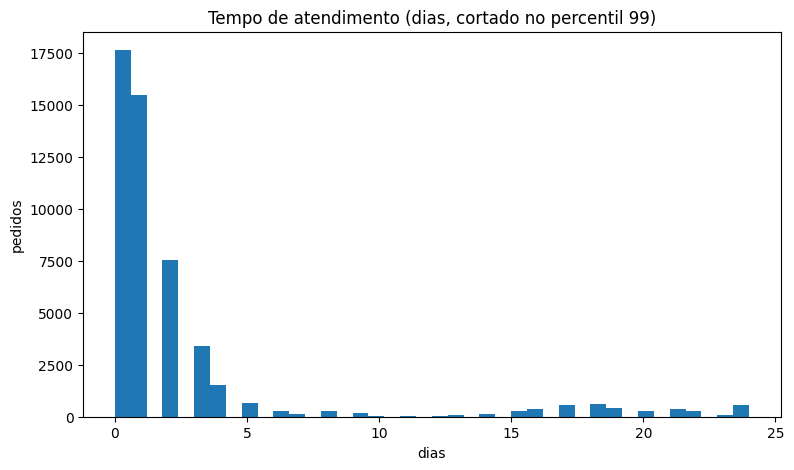

In [21]:
df_fin = df_t[(df_t['status_norm'] == 'finalizada') & df_t['tempo_dias'].notna()].copy()  # pedidos com tempo medido
print(f'Pedidos do tema: {len(df_t):,} | finalizados com tempo válido: {len(df_fin):,}')
print('\nTempo de atendimento (dias) dos finalizados:')
display(df_fin['tempo_dias'].describe(percentiles=[.5, .75, .9, .99]).round(1).to_frame('dias'))
limite_graf = df_fin['tempo_dias'].quantile(0.99)                       # corta a cauda longa só no gráfico
df_fin['tempo_dias'].clip(upper=limite_graf).plot.hist(bins=40)         # histograma do tempo
plt.title('Tempo de atendimento (dias, cortado no percentil 99)'); plt.xlabel('dias'); plt.ylabel('pedidos'); plt.show()

In [22]:
# Pedidos ainda abertos: quantos são e há quanto tempo estão esperando
abertos = df_t[df_t['status_norm'].isin(['aberta', 'em andamento'])]
print(f'Em aberto: {len(abertos):,} ({len(abertos)/len(df_t):.1%}) | idade mediana: {abertos["idade_dias"].median():.0f} dias')
display(df_t['status_norm'].value_counts().to_frame('pedidos'))

Em aberto: 2,871 (5.3%) | idade mediana: 38 dias


,pedidos
status_norm,
finalizada,51388
aberta,2869
cancelada,53
em andamento,2


In [23]:
# Limites de atraso: por serviço, calculados a partir de uma tabela de referência
def calcular_limiares(ref):
    # limite do serviço = percentil PCT_ATRASO dos tempos (só serviços com pedidos suficientes)
    n = ref.groupby('Serviço').size()
    lim = ref.groupby('Serviço')['tempo_dias'].quantile(PCT_ATRASO)
    lim = lim[n >= MIN_REG_SERVICO]
    lim_geral = ref['tempo_dias'].quantile(PCT_ATRASO)        # usado quando o serviço é raro
    return lim, lim_geral

def marcar_atraso(tab, lim, lim_geral):
    # prioridade: prazo da Carta de Serviços (se informado) > limite do serviço > limite geral
    limite = tab['Serviço'].map(PRAZO_CARTA).fillna(tab['Serviço'].map(lim)).fillna(lim_geral)
    return (tab['tempo_dias'] > limite).astype(int), limite   # 1 = demorou mais que o limite

In [24]:
# ATENÇÃO: aqui o limite usa TODA a base, só para explorar. No modelo (seção 4) ele é recalculado só com o treino.
lim_eda, lim_geral_eda = calcular_limiares(df_fin)
df_fin['atraso_eda'], _ = marcar_atraso(df_fin, lim_eda, lim_geral_eda)
print('Proporção de atrasos (exploração):', round(df_fin['atraso_eda'].mean(), 3))

def resumo_por(coluna):
    # tabela por distrito OU prefeitura: volume, % em aberto, tempo mediano, tempo p90, % de atraso
    base = df_t[df_t[coluna] != 'NAO INFORMADO']
    fin = df_fin[df_fin[coluna] != 'NAO INFORMADO']
    vol = base.groupby(coluna).size().rename('pedidos')
    aberto = base.groupby(coluna)['status_norm'].apply(lambda s: s.isin(['aberta', 'em andamento']).mean() * 100).rename('pct_em_aberto')
    tempo = fin.groupby(coluna)['tempo_dias'].agg(tempo_mediano='median', tempo_p90=lambda s: s.quantile(0.9))
    atraso = (fin.groupby(coluna)['atraso_eda'].mean() * 100).rename('pct_atraso')
    tab = pd.concat([vol, aberto, tempo, atraso], axis=1).round(1)
    return tab[tab['pedidos'] >= MIN_PEDIDOS_DISTRITO].sort_values('pedidos', ascending=False)

Proporção de atrasos (exploração): 0.2


In [25]:
tab_dist = resumo_por('Distrito')
print(f'Distritos com pelo menos {MIN_PEDIDOS_DISTRITO} pedidos: {len(tab_dist)}')
display(tab_dist.head(20))

Distritos com pelo menos 50 pedidos: 95


,pedidos,pct_em_aberto,tempo_mediano,tempo_p90,pct_atraso
Distrito,,,,,
JABAQUARA,2238,1.3,0.0,16.0,18.7
ITAQUERA,1500,2.1,1.0,4.0,17.5
BRASILANDIA,1407,5.1,1.0,4.0,20.8
GRAJAU,1249,5.3,1.0,7.0,24.5
VILA MEDEIROS,1212,3.7,1.0,4.4,13.4
BELEM,1170,5.0,0.0,3.0,12.6
CIDADE ADEMAR,1128,2.3,1.0,6.0,23.6
CIDADE DUTRA,1079,3.4,1.0,8.0,24.8
CAPAO REDONDO,1047,3.7,1.0,4.0,13.7


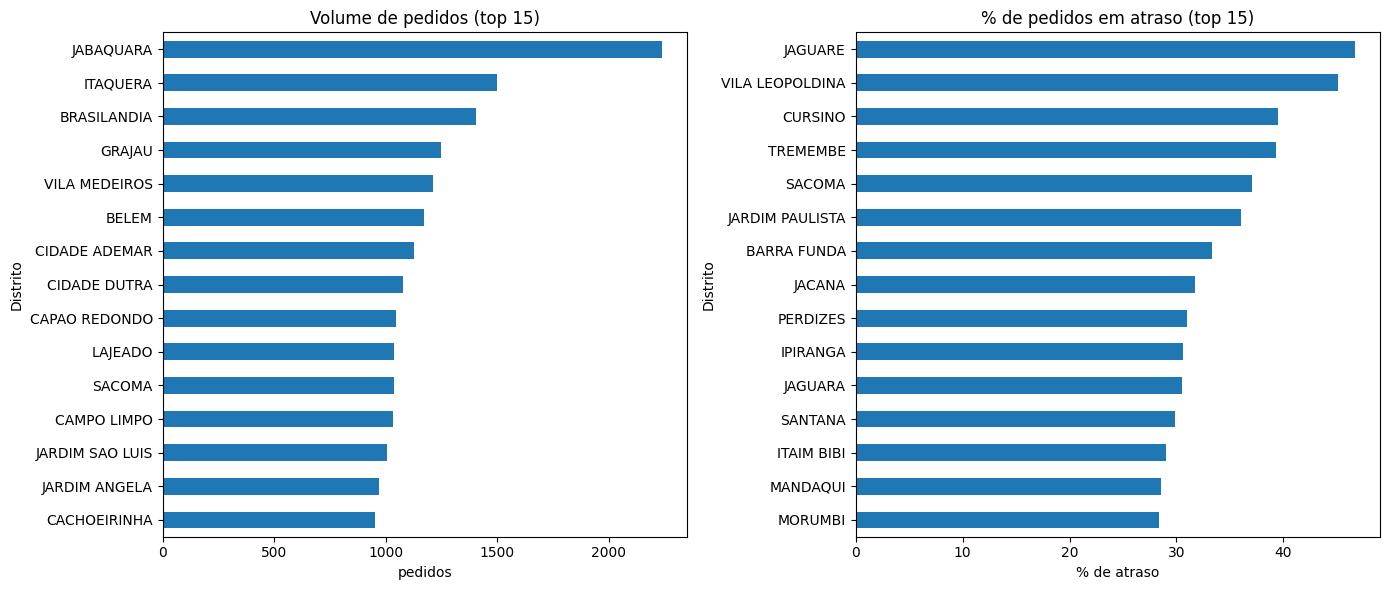

In [26]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 6))
tab_dist.head(15).sort_values('pedidos')['pedidos'].plot.barh(ax=eixos[0])        # 15 distritos com mais pedidos
eixos[0].set_title('Volume de pedidos (top 15)'); eixos[0].set_xlabel('pedidos')
tab_dist.sort_values('pct_atraso').tail(15)['pct_atraso'].plot.barh(ax=eixos[1])  # 15 com maior % de atraso
eixos[1].set_title('% de pedidos em atraso (top 15)'); eixos[1].set_xlabel('% de atraso')
plt.tight_layout(); plt.show()

,pedidos,pct_em_aberto,tempo_mediano,tempo_p90,pct_atraso
Prefeitura Operacional,,,,,
ITAQUERA,3197,2.3,1.0,4.0,17.7
MOOCA,2955,7.7,1.0,4.0,14.1
BUTANTA,2837,5.1,1.0,4.0,23.8
CAPELA DO SOCORRO,2621,4.3,1.0,7.0,24.1
SE,2582,9.3,0.0,4.0,13.0
CAMPO LIMPO,2396,3.3,1.0,4.0,14.9
PENHA,2393,8.1,1.0,5.0,16.6
IPIRANGA,2329,2.6,2.0,16.0,36.0
JABAQUARA,2168,1.3,0.0,16.0,18.5


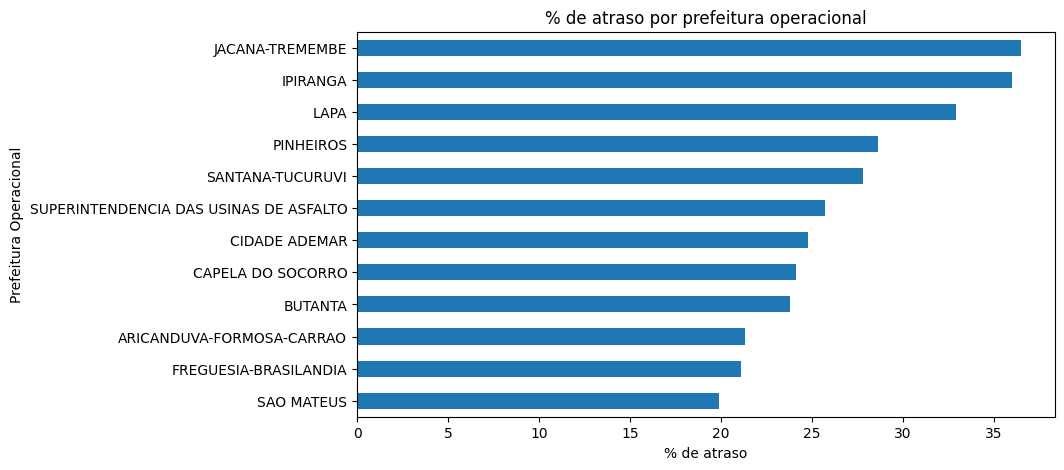

In [27]:
tab_pref = resumo_por('Prefeitura Operacional')    # mesma análise por subprefeitura (prefeitura operacional)
display(tab_pref.head(15))
tab_pref.sort_values('pct_atraso').tail(12)['pct_atraso'].plot.barh()
plt.title('% de atraso por prefeitura operacional'); plt.xlabel('% de atraso'); plt.show()

In [28]:
# OPCIONAL: normalizar por população. Prepare um CSV com colunas 'Distrito' e 'populacao' (ex.: Censo IBGE 2022).
if POP_CSV:
    pop = pd.read_csv(POP_CSV)
    pop['Distrito'] = normalizar(pop['Distrito'], 'upper')               # mesmo padrão de nomes da base
    t = tab_dist.reset_index().merge(pop[['Distrito', 'populacao']], on='Distrito', how='left')
    t['pedidos_por_10mil_hab'] = (t['pedidos'] / t['populacao'] * 10000).round(1)
    display(t.sort_values('pedidos_por_10mil_hab', ascending=False).head(15))
else:
    print('POP_CSV não informado: volumes brutos NÃO estão normalizados por população.')

POP_CSV não informado: volumes brutos NÃO estão normalizados por população.


In [29]:
# Ajuda para escolher o bairro: lista os distritos que aparecem entre os extremos de cada métrica
print('Mais pedidos       :', list(tab_dist.sort_values('pedidos').tail(5).index[::-1]))
print('Maior % de atraso  :', list(tab_dist.sort_values('pct_atraso').tail(5).index[::-1]))
print('Maior tempo p90    :', list(tab_dist.sort_values('tempo_p90').tail(5).index[::-1]))
print('Maior % em aberto  :', list(tab_dist.sort_values('pct_em_aberto').tail(5).index[::-1]))

Mais pedidos       : ['JABAQUARA', 'ITAQUERA', 'BRASILANDIA', 'GRAJAU', 'VILA MEDEIROS']
Maior % de atraso  : ['JAGUARE', 'VILA LEOPOLDINA', 'CURSINO', 'TREMEMBE', 'SACOMA']
Maior tempo p90    : ['JARDIM PAULISTA', 'JACANA', 'IPIRANGA', 'JABAQUARA', 'CAMPO BELO']
Maior % em aberto  : ['JARDIM PAULISTA', 'ALTO DE PINHEIROS', 'PERUS', 'VILA LEOPOLDINA', 'ITAIM BIBI']


**Como escolher o bairro:** combine volume (há dados suficientes?), % de atraso e tempo p90 (o problema é sentido pelo cidadão?), e lembre do viés de registro. Anote a justificativa no relatório e preencha `BAIRRO_ESCOLHIDO` nos parâmetros. O modelo usa a cidade inteira (mais dados); o bairro entra na leitura dos resultados (seção 7).

## 4. Preparação e divisão treino/teste
**Quem entra no modelo:** pedidos `finalizada` com tempo válido e abertos há pelo menos `JANELA_MIN_DIAS` dias antes da data de corte. Sem essa janela, só os pedidos rápidos de fim de setembro estariam finalizados, e o modelo aprenderia uma realidade mais otimista do que a verdadeira.

**Divisão:** por **endereço** (`GroupShuffleSplit`). Pedidos do mesmo endereço costumam ser fechados juntos; se um ficasse no treino e outro no teste, o modelo "colaria". Assim nenhum endereço aparece nos dois lados.

In [30]:
passos = {}                                                                  # conta quantos pedidos sobram em cada filtro
df_m = df_t.copy();                                          passos['1. Pedidos do tema (sem duplicadas)'] = len(df_m)
df_m = df_m[df_m['status_norm'] == 'finalizada'];            passos['2. Somente finalizados'] = len(df_m)
df_m = df_m[df_m['tempo_dias'].notna()];                     passos['3. Com tempo de atendimento válido'] = len(df_m)
df_m = df_m[df_m['idade_dias'] >= JANELA_MIN_DIAS];          passos[f'4. Abertos há ≥ {JANELA_MIN_DIAS} dias da data de corte'] = len(df_m)
display(pd.Series(passos).to_frame('linhas'))

,linhas
1. Pedidos do tema (sem duplicadas),54312
2. Somente finalizados,51388
3. Com tempo de atendimento válido,51388
4. Abertos há ≥ 30 dias da data de corte,39378


In [31]:
# Variáveis que o modelo PODE usar: tudo o que já se sabe NO MOMENTO em que o pedido é aberto
df_m['mes_abertura'] = df_m['Data de Abertura'].dt.month        # mês (7, 8 ou 9)
df_m['dia_semana'] = df_m['Data de Abertura'].dt.dayofweek      # 0 = segunda ... 6 = domingo
df_m['dia_do_mes'] = df_m['Data de Abertura'].dt.day            # dia do mês
COL_CAT = ['Serviço', 'Assunto', 'Meio de Comunicação', 'Distrito', 'Prefeitura Operacional']   # categorias (texto)
COL_CAL = ['mes_abertura', 'dia_do_mes']                                   # calendário (ver seção 5b: carregam o "episódio" de julho)
COL_NUM = ['Latitude', 'Longitude', 'dia_semana'] + (COL_CAL if USAR_CALENDARIO else [])   # números
FEATURES = COL_CAT + COL_NUM
print('Usando calendário (mês e dia do mês)?', USAR_CALENDARIO)
print('Variáveis do modelo:', FEATURES)

Usando calendário (mês e dia do mês)? False
Variáveis do modelo: ['Serviço', 'Assunto', 'Meio de Comunicação', 'Distrito', 'Prefeitura Operacional', 'Latitude', 'Longitude', 'dia_semana']


In [32]:
# Grupo = endereço (logradouro + número). Pedido sem endereço vira um grupo só dele.
chave = (df_m['Logradouro'].fillna('') + '|' + df_m['Número'].fillna('')).str.upper()
unico = pd.Series('SEM_ENDERECO_' + df_m.index.astype(str), index=df_m.index)
df_m['grupo'] = chave.where(df_m['Logradouro'].notna(), unico)
print('Endereços distintos:', df_m['grupo'].nunique(), '| pedidos:', len(df_m))

Endereços distintos: 27847 | pedidos: 39378


In [33]:
divisor = GroupShuffleSplit(n_splits=1, test_size=TESTE_PROPORCAO, random_state=SEED)  # 1 divisão, semente fixa
idx_treino, idx_teste = next(divisor.split(df_m, groups=df_m['grupo']))                # posições das linhas de cada lado
treino = df_m.iloc[idx_treino].copy()                                                  # 80% para aprender
teste = df_m.iloc[idx_teste].copy()                                                    # 20% guardados só para avaliar
print('Treino:', len(treino), '| Teste:', len(teste))

Treino: 31523 | Teste: 7855


In [34]:
# O limite de atraso é calculado SÓ com o treino e depois aplicado ao teste (evita vazamento)
lim_tr, lim_geral_tr = calcular_limiares(treino)
treino['atraso'], treino['limite_dias'] = marcar_atraso(treino, lim_tr, lim_geral_tr)
teste['atraso'], teste['limite_dias'] = marcar_atraso(teste, lim_tr, lim_geral_tr)
print(f'Limite geral (percentil {PCT_ATRASO:.0%}): {lim_geral_tr:.0f} dias')
display(lim_tr.rename('limite_dias').to_frame())
print(f'% de atrasos no treino: {treino["atraso"].mean():.1%} | no teste: {teste["atraso"].mean():.1%}')
X_treino, y_treino, g_treino = treino[FEATURES], treino['atraso'], treino['grupo']    # X = entradas, y = resposta
X_teste, y_teste = teste[FEATURES], teste['atraso']

Limite geral (percentil 75%): 2 dias


,limite_dias
Serviço,
Cata Bagulho - Fazer reclamação de não retirada de material,2.00
Coleta seletiva - Solicitar manutenção de contêiner,3.00
Denunciar caçamba irregular de entulho de construção,31.25
Denunciar descarte irregular de entulho e outros resíduos em área pública,0.00
Denúncia de grande gerador de resíduos colocando lixo na coleta normal,62.00
Denúncia de má conduta dos funcionários (motoristas /coletores),4.00
Denúncia de má conduta dos funcionários de limpeza,1.00
Entulho e grandes objetos em via pública - solicitar remoção,2.00
Fazer reclamação de falta de lavagem de calçadões,2.00


% de atrasos no treino: 21.1% | no teste: 21.5%


## 5. Checagem de vazamento de dados
Vazamento é quando o modelo "vê" na entrada algo que só se saberia depois (ou que repete o teste no treino). Ele deixa a nota bonita e o resultado falso. Cinco checagens:

In [35]:
# 1) Nenhuma coluna proibida entre as variáveis do modelo
PROIBIDAS = ['Data de Finalização', 'tempo_dias', 'status_norm', 'Status', 'Órgão', 'idade_dias', 'atraso', 'limite_dias']
vazadas = [c for c in PROIBIDAS if c in FEATURES]
print('1) Colunas proibidas nas variáveis:', vazadas)
assert not vazadas
# Por quê: Finalização e tempo definem o alvo; Status e Órgão são o retrato do dia da extração (o Órgão pode mudar depois da abertura).

1) Colunas proibidas nas variáveis: []


In [36]:
# 2) Nenhum endereço aparece no treino e no teste ao mesmo tempo
repetidos = set(treino['grupo']) & set(teste['grupo'])
print('2) Endereços nos dois lados:', len(repetidos))
assert len(repetidos) == 0

2) Endereços nos dois lados: 0


In [37]:
# 3) Nenhuma linha completa (todas as colunas originais) aparece repetida entre treino e teste
repetidas = int(pd.concat([treino, teste]).duplicated(subset=ESPERADAS).sum())   # duplicadas na junção treino+teste
print('3) Linhas completas repetidas entre treino e teste:', repetidas)
assert repetidas == 0   # só vale se REMOVER_DUPLICADAS = True

3) Linhas completas repetidas entre treino e teste: 0


In [38]:
# 4) Limite de atraso calculado só com o treino
print('4) Serviços com limite próprio calculado do treino:', len(lim_tr), '| limite geral do treino:', lim_geral_tr)
print('   (a função calcular_limiares só recebeu a tabela "treino" na seção 4)')

4) Serviços com limite próprio calculado do treino: 27 | limite geral do treino: 2.0
   (a função calcular_limiares só recebeu a tabela "treino" na seção 4)


In [39]:
# 5) Uma variável sozinha não deveria prever bem. Acima de 0,70 de AUC já é sinal para investigar (acima de 0,90, quase certo problema).
resultados = []
for col in FEATURES:
    prep = OneHotEncoder(handle_unknown='ignore', min_frequency=20) if col in COL_CAT else SimpleImputer(strategy='median')
    arvore = Pipeline([('prep', ColumnTransformer([('c', prep, [col])])),
                       ('arv', DecisionTreeClassifier(max_depth=4, random_state=SEED))])
    arvore.fit(X_treino, y_treino)                                              # aprende com UMA coluna, no treino
    auc = roc_auc_score(y_teste, arvore.predict_proba(X_teste)[:, 1])           # mede no teste
    resultados.append((col, round(auc, 3)))
auc_uma_variavel = pd.DataFrame(resultados, columns=['variável', 'AUC sozinha']).sort_values('AUC sozinha', ascending=False)
display(auc_uma_variavel)
print('5) Variáveis acima de 0,70:', list(auc_uma_variavel.loc[auc_uma_variavel['AUC sozinha'] > 0.70, 'variável']))

,variável,AUC sozinha
7,dia_semana,0.579
4,Prefeitura Operacional,0.548
5,Latitude,0.537
0,Serviço,0.535
6,Longitude,0.533
3,Distrito,0.524
1,Assunto,0.519
2,Meio de Comunicação,0.511


5) Variáveis acima de 0,70: []


> **Nota:** como o limite de atraso é relativo ao próprio serviço, saber *qual serviço* é não ajuda a prever o atraso. O modelo precisa achar sinal em **onde, quando e por qual canal** o pedido foi feito. Isso torna a tarefa mais difícil e o resultado, mais honesto.

## 5b. Diagnóstico do calendário
Na primeira execução completa (3º tri/2026), o modelo com calendário teve AUC ≈ 0,93, mas as variáveis mais importantes eram `dia_do_mes` e `mes_abertura`. Esta seção investiga se isso é um padrão da cidade ou um efeito do calendário operacional.

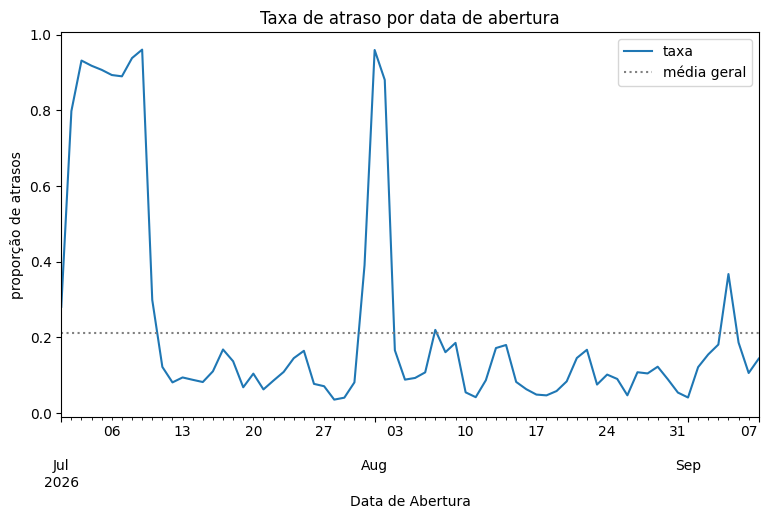

Taxa de atraso por mês de abertura:


,mean,size
mes_abertura,,
7,0.301,18180
8,0.134,17294
9,0.148,3904


Datas de finalização mais frequentes (fechamento concentrado?):


,finalizados
Data de Finalização,
2026-07-24,2765
2026-08-05,1458
2026-07-25,1082
2026-07-30,1053
2026-07-27,1022
2026-08-07,933
2026-08-12,842
2026-07-23,833
2026-07-21,779


In [40]:
dg = pd.concat([treino, teste])                                          # todos os pedidos do modelo, com a marcação de atraso
taxa_dia = dg.groupby('Data de Abertura')['atraso'].agg(taxa='mean', pedidos='size')   # taxa de atraso por dia de abertura
taxa_dia['taxa'].plot(); plt.axhline(dg['atraso'].mean(), color='gray', linestyle=':', label='média geral')
plt.title('Taxa de atraso por data de abertura'); plt.ylabel('proporção de atrasos'); plt.legend(); plt.show()
print('Taxa de atraso por mês de abertura:'); display(dg.groupby('mes_abertura')['atraso'].agg(['mean', 'size']).round(3))
print('Datas de finalização mais frequentes (fechamento concentrado?):'); display(dg['Data de Finalização'].value_counts().head(10).to_frame('finalizados'))

In [41]:
# Dias "atípicos": taxa de atraso muito acima do normal. Definido olhando o RESULTADO, por isso é só análise de sensibilidade.
DIAS_ATIPICOS = taxa_dia[(taxa_dia['taxa'] > LIMIAR_DIA_ATIPICO) & (taxa_dia['pedidos'] >= 50)].index
print(f'{len(DIAS_ATIPICOS)} dias atípicos:', [d.strftime('%d/%m') for d in DIAS_ATIPICOS])
pct = dg['Data de Abertura'].isin(DIAS_ATIPICOS).mean()
print(f'Eles concentram {pct:.1%} dos pedidos e {dg.loc[dg["Data de Abertura"].isin(DIAS_ATIPICOS), "atraso"].sum() / dg["atraso"].sum():.1%} dos atrasos.')

10 dias atípicos: ['02/07', '03/07', '04/07', '05/07', '06/07', '07/07', '08/07', '09/07', '01/08', '02/08']
Eles concentram 12.4% dos pedidos e 52.7% dos atrasos.


**Leitura:** se poucos dias respondem por boa parte dos atrasos e as finalizações se concentram em poucas datas, o "atraso" desse trimestre vem em grande parte de episódios operacionais (acúmulo de pedidos fechados em lote, mudança de processo ou outra causa que a base não registra). Um modelo com mês e dia do mês aprende **em que dia o pedido foi aberto**, não **onde ou como**. Por isso o modelo principal roda **sem** essas duas variáveis, e o modelo com calendário aparece na análise de sensibilidade (seção 7b) como comparação.

## 6. Modelo e busca de hiperparâmetros
**Por que Random Forest?**
- Os dados são **tabulares**, com categorias (serviço, distrito, canal) e números (coordenadas, data). Árvores lidam bem com essa mistura e com relações não lineares.
- Não exige padronizar escalas e é pouco sensível a valores extremos.
- A "floresta" combina muitas árvores diferentes, o que reduz o overfitting de uma árvore só.
- Tem poucos hiperparâmetros e permite medir a importância das variáveis, fáceis de explicar.
- Descartados: LSTM (não há sequência temporal por pessoa), MLP (exige mais dados e é difícil de interpretar), KMeans+PCA (não supervisionado). XGBoost seria uma alternativa válida, mas tem mais hiperparâmetros e muda de comportamento com pouca regulagem.

In [42]:
prep = ColumnTransformer([
    ('categorias', OneHotEncoder(handle_unknown='ignore', min_frequency=20), COL_CAT),  # texto -> colunas 0/1 (raros agrupados)
    ('numeros', SimpleImputer(strategy='median'), COL_NUM)])                            # número faltante -> mediana do TREINO
pipe = Pipeline([('prep', prep),
                 ('rf', RandomForestClassifier(random_state=SEED, n_jobs=-1, class_weight='balanced'))])
# class_weight='balanced': como há menos atrasos que pedidos no prazo, dá mais peso aos atrasos
# O Pipeline faz a preparação DENTRO de cada dobra, então nada do conjunto de validação "vaza" para o aprendizado.

In [43]:
# Comparação: modelo "bobo" que sorteia respostas na mesma proporção do treino
base = DummyClassifier(strategy='stratified', random_state=SEED).fit(X_treino, y_treino)
print('Acurácia de "sempre prever no prazo":', round(1 - y_teste.mean(), 3), '(parece boa, mas não detecta nenhum atraso)')

Acurácia de "sempre prever no prazo": 0.785 (parece boa, mas não detecta nenhum atraso)


In [44]:
grade = {'rf__n_estimators': [100, 300],        # nº de árvores
         'rf__max_depth': [8, 16, None],        # profundidade máxima (None = sem limite)
         'rf__min_samples_leaf': [1, 10, 30]}   # mínimo de pedidos por folha (maior = árvore mais simples)
n_comb = int(np.prod([len(v) for v in grade.values()]))
print(f'{n_comb} combinações x {CV_FOLDS} dobras = {n_comb * CV_FOLDS} treinos (pode levar alguns minutos)')
busca = GridSearchCV(pipe, grade,
                     cv=GroupKFold(n_splits=CV_FOLDS),   # validação cruzada SÓ no treino, sem repetir endereço entre dobras
                     scoring='f1',                       # equilibra acertar atrasos e não dar alarme falso
                     return_train_score=True,            # guarda a nota no treino para ver overfitting
                     n_jobs=1, refit=True)               # refit: reaprende o melhor modelo com todo o treino

18 combinações x 5 dobras = 90 treinos (pode levar alguns minutos)


In [45]:
busca.fit(X_treino, y_treino, groups=g_treino)           # roda a busca (usa só o treino)
print('Melhor combinação:', busca.best_params_)
print('F1 médio na validação cruzada:', round(busca.best_score_, 3))
modelo = busca.best_estimator_                           # modelo final, já treinado com todo o treino

Melhor combinação: {'rf__max_depth': None, 'rf__min_samples_leaf': 10, 'rf__n_estimators': 300}
F1 médio na validação cruzada: 0.409


In [46]:
cv = pd.DataFrame(busca.cv_results_)                     # resultado de todas as combinações
tab_cv = cv[['param_rf__n_estimators', 'param_rf__max_depth', 'param_rf__min_samples_leaf',
             'mean_train_score', 'mean_test_score', 'std_test_score', 'mean_fit_time', 'rank_test_score']].copy()
tab_cv.columns = ['n_arvores', 'profundidade', 'min_amostras_folha', 'F1_treino_dobras',
                  'F1_validacao_dobras', 'desvio_validacao', 'tempo_s', 'ranking']
tab_cv = tab_cv.sort_values('ranking').round(3)
display(tab_cv)

,n_arvores,profundidade,min_amostras_folha,F1_treino_dobras,F1_validacao_dobras,desvio_validacao,tempo_s,ranking
15,300,None,10,0.497,0.409,0.011,16.904,1
14,100,None,10,0.495,0.406,0.012,6.058,2
9,300,16,10,0.438,0.400,0.012,7.810,3
17,300,None,30,0.438,0.399,0.010,10.383,4
8,100,16,10,0.437,0.399,0.010,2.752,5
16,100,None,30,0.437,0.399,0.012,3.449,6
10,100,16,30,0.418,0.394,0.011,2.388,7
1,300,8,1,0.421,0.393,0.010,4.954,8
11,300,16,30,0.419,0.393,0.009,6.920,9
0,100,8,1,0.421,0.392,0.010,3.434,10


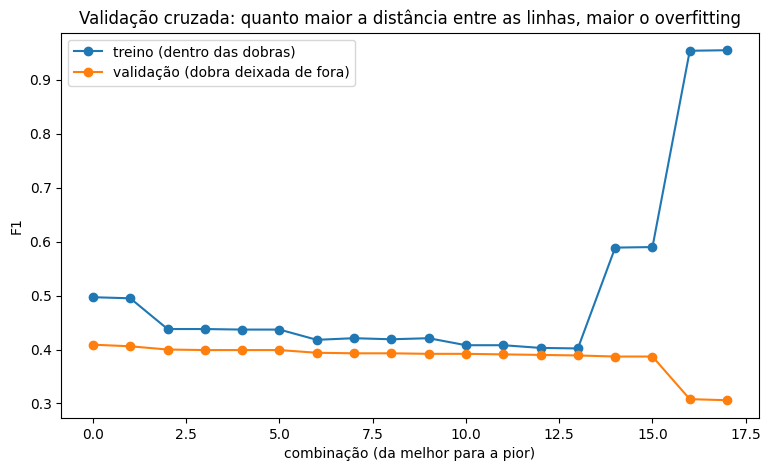

In [47]:
ordem = tab_cv.reset_index(drop=True)                    # gráfico: nota de treino x validação por combinação
plt.plot(ordem.index, ordem['F1_treino_dobras'], marker='o', label='treino (dentro das dobras)')
plt.plot(ordem.index, ordem['F1_validacao_dobras'], marker='o', label='validação (dobra deixada de fora)')
plt.xlabel('combinação (da melhor para a pior)'); plt.ylabel('F1'); plt.legend()
plt.title('Validação cruzada: quanto maior a distância entre as linhas, maior o overfitting'); plt.show()

## 7. Resultados: treino x teste

In [48]:
def metricas(mod, X, y):
    pred = mod.predict(X)                                # classe prevista (0 ou 1)
    prob = mod.predict_proba(X)[:, 1]                    # probabilidade de atraso
    return {'acurácia': accuracy_score(y, pred), 'precisão': precision_score(y, pred, zero_division=0),
            'recall': recall_score(y, pred), 'F1': f1_score(y, pred), 'AUC': roc_auc_score(y, prob)}

res = pd.DataFrame({'Treino': metricas(modelo, X_treino, y_treino),     # nota nos dados que o modelo viu
                    'Teste': metricas(modelo, X_teste, y_teste),        # nota nos dados que ele nunca viu
                    'Sorteio (comparação)': metricas(base, X_teste, y_teste)}).round(3)
display(res)

,Treino,Teste,Sorteio (comparação)
acurácia,0.707,0.657,0.668
precisão,0.390,0.329,0.221
recall,0.679,0.571,0.215
F1,0.495,0.417,0.218
AUC,0.777,0.680,0.503


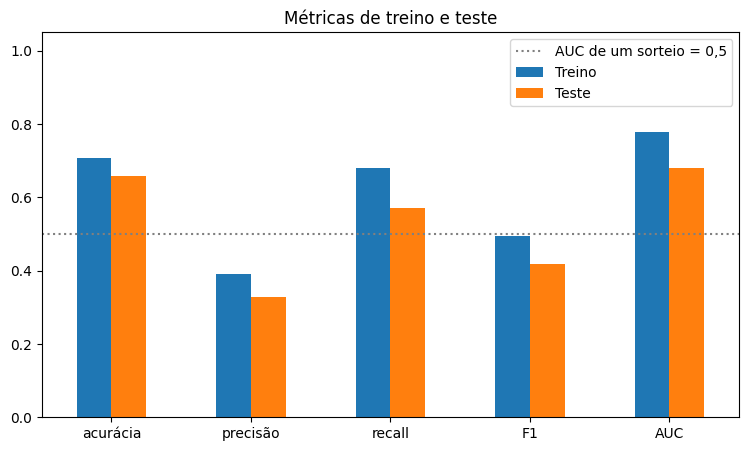

In [49]:
res[['Treino', 'Teste']].plot.bar(rot=0)                 # barras lado a lado: treino x teste
plt.axhline(0.5, color='gray', linestyle=':', label='AUC de um sorteio = 0,5')
plt.title('Métricas de treino e teste'); plt.ylim(0, 1.05); plt.legend(); plt.show()

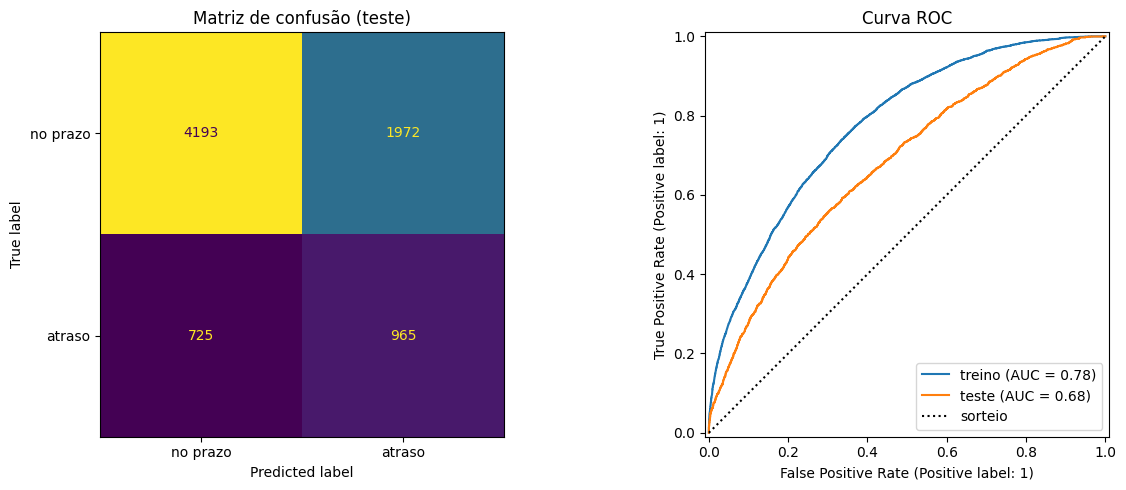

In [50]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_estimator(modelo, X_teste, y_teste, ax=eixos[0], colorbar=False,
                                      display_labels=['no prazo', 'atraso'])   # acertos e erros no teste
eixos[0].set_title('Matriz de confusão (teste)')
RocCurveDisplay.from_estimator(modelo, X_treino, y_treino, ax=eixos[1], name='treino')   # curva ROC do treino
RocCurveDisplay.from_estimator(modelo, X_teste, y_teste, ax=eixos[1], name='teste')      # curva ROC do teste
eixos[1].plot([0, 1], [0, 1], 'k:', label='sorteio'); eixos[1].legend(); eixos[1].set_title('Curva ROC')
plt.tight_layout(); plt.show()

In [51]:
# Overfitting = ir bem no treino e mal no teste (o modelo decorou em vez de aprender)
f1_tr, f1_te = res.loc['F1', 'Treino'], res.loc['F1', 'Teste']
auc_tr, auc_te = res.loc['AUC', 'Treino'], res.loc['AUC', 'Teste']
melhor = tab_cv.iloc[0]
print(f'F1  treino {f1_tr:.3f} x teste {f1_te:.3f} | diferença {f1_tr - f1_te:.3f}')
print(f'AUC treino {auc_tr:.3f} x teste {auc_te:.3f} | diferença {auc_tr - auc_te:.3f}')
print(f'Validação cruzada (melhor combinação): treino {melhor["F1_treino_dobras"]:.3f} x validação {melhor["F1_validacao_dobras"]:.3f}')
dif = f1_tr - f1_te
nivel = 'forte' if dif > 0.15 else 'moderado' if dif > 0.05 else 'baixo'
print(f'-> Sinal de overfitting {nivel} (regra prática: >0,15 forte, 0,05 a 0,15 moderado).')

F1  treino 0.495 x teste 0.417 | diferença 0.078
AUC treino 0.777 x teste 0.680 | diferença 0.097
Validação cruzada (melhor combinação): treino 0.497 x validação 0.409
-> Sinal de overfitting moderado (regra prática: >0,15 forte, 0,05 a 0,15 moderado).


,queda_no_F1
dia_semana,0.0753
Prefeitura Operacional,0.0255
Assunto,0.0157
Meio de Comunicação,0.0148
Longitude,0.0124
Distrito,0.0114
Serviço,0.0112
Latitude,0.0106


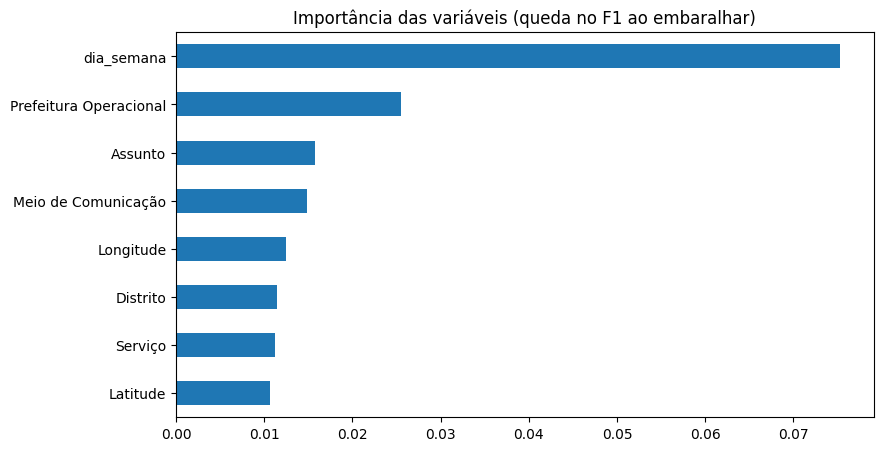

In [52]:
# Quais variáveis mais ajudam? Embaralhamos uma coluna do TESTE e vemos quanto o F1 cai.
amostra = X_teste.sample(min(5000, len(X_teste)), random_state=SEED)      # amostra para não demorar
imp = permutation_importance(modelo, amostra, y_teste.loc[amostra.index], scoring='f1',
                             n_repeats=5, random_state=SEED, n_jobs=-1)
tab_imp = pd.Series(imp.importances_mean, index=FEATURES).sort_values(ascending=False)
display(tab_imp.round(4).to_frame('queda_no_F1'))
tab_imp.head(10).sort_values().plot.barh(); plt.title('Importância das variáveis (queda no F1 ao embaralhar)'); plt.show()

In [53]:
# Desempenho por distrito no TESTE (só distritos com pelo menos 30 pedidos de teste)
teste['previsto'] = modelo.predict(X_teste)
por_dist = teste.groupby('Distrito').agg(pedidos_teste=('atraso', 'size'),
                                        atraso_real_pct=('atraso', lambda s: s.mean() * 100),
                                        alertas_modelo_pct=('previsto', lambda s: s.mean() * 100)).round(1)
display(por_dist[por_dist['pedidos_teste'] >= 30].sort_values('pedidos_teste', ascending=False).head(15))
if BAIRRO_ESCOLHIDO:
    b = sem_acento(BAIRRO_ESCOLHIDO).upper()
    sub = teste[teste['Distrito'] == b]
    print(f'{b}: {len(sub)} pedidos no teste', end=' | ')
    print(f'atraso real {sub["atraso"].mean():.1%}' if len(sub) else 'sem pedidos no teste')

,pedidos_teste,atraso_real_pct,alertas_modelo_pct
Distrito,,,
JABAQUARA,340,22.6,42.9
ITAQUERA,250,14.4,15.2
BRASILANDIA,236,23.7,32.2
VILA MEDEIROS,183,16.4,32.8
CAPAO REDONDO,179,17.9,16.8
GRAJAU,172,27.3,44.2
CIDADE LIDER,163,18.4,31.3
CAMPO LIMPO,159,18.9,35.2
CIDADE DUTRA,158,25.9,50.0


JABAQUARA: 340 pedidos no teste | atraso real 22.6%


## 7b. Análise de sensibilidade
Mesmos hiperparâmetros do melhor modelo (sem nova busca), três cenários. Cada cenário refaz a divisão por endereço e o limite de atraso só com o seu treino, então os conjuntos de teste não são idênticos.

In [54]:
def rodar_cenario(nome, usar_cal, sem_atipicos):
    base_c = df_m[~df_m['Data de Abertura'].isin(DIAS_ATIPICOS)] if sem_atipicos else df_m   # tira os dias atípicos (se pedido)
    feats_c = COL_CAT + ['Latitude', 'Longitude', 'dia_semana'] + (COL_CAL if usar_cal else [])
    num_c = [c for c in feats_c if c not in COL_CAT]
    i_tr, i_te = next(GroupShuffleSplit(n_splits=1, test_size=TESTE_PROPORCAO, random_state=SEED).split(base_c, groups=base_c['grupo']))
    tr, te = base_c.iloc[i_tr].copy(), base_c.iloc[i_te].copy()
    lim, lim_g = calcular_limiares(tr)                                   # limite de atraso só com o treino do cenário
    tr['atraso'], _ = marcar_atraso(tr, lim, lim_g); te['atraso'], _ = marcar_atraso(te, lim, lim_g)
    bp = busca.best_params_                                              # hiperparâmetros do melhor modelo
    rf = RandomForestClassifier(n_estimators=bp['rf__n_estimators'], max_depth=bp['rf__max_depth'],
                                min_samples_leaf=bp['rf__min_samples_leaf'], random_state=SEED, n_jobs=-1, class_weight='balanced')
    prep_c = ColumnTransformer([('categorias', OneHotEncoder(handle_unknown='ignore', min_frequency=20), COL_CAT),
                                ('numeros', SimpleImputer(strategy='median'), num_c)])
    m = Pipeline([('prep', prep_c), ('rf', rf)]).fit(tr[feats_c], tr['atraso'])
    pred, prob = m.predict(te[feats_c]), m.predict_proba(te[feats_c])[:, 1]
    return {'cenário': nome, 'pedidos_teste': len(te), '% atrasos (teste)': round(te['atraso'].mean() * 100, 1),
            'precisão': round(precision_score(te['atraso'], pred, zero_division=0), 3),
            'recall': round(recall_score(te['atraso'], pred), 3), 'F1': round(f1_score(te['atraso'], pred), 3),
            'AUC': round(roc_auc_score(te['atraso'], prob), 3)}

sens = pd.DataFrame([rodar_cenario('A. com calendário', True, False),
                     rodar_cenario('B. sem calendário', False, False),
                     rodar_cenario('C. sem calendário e sem dias atípicos', False, True)]).set_index('cenário')
display(sens)
auc_A, auc_B, auc_C = sens['AUC'].tolist()

,pedidos_teste,% atrasos (teste),precisão,recall,F1,AUC
cenário,,,,,,
A. com calendário,7855,21.5,0.676,0.757,0.714,0.912
B. sem calendário,7855,21.5,0.329,0.571,0.417,0.680
C. sem calendário e sem dias atípicos,6919,21.6,0.399,0.680,0.503,0.770


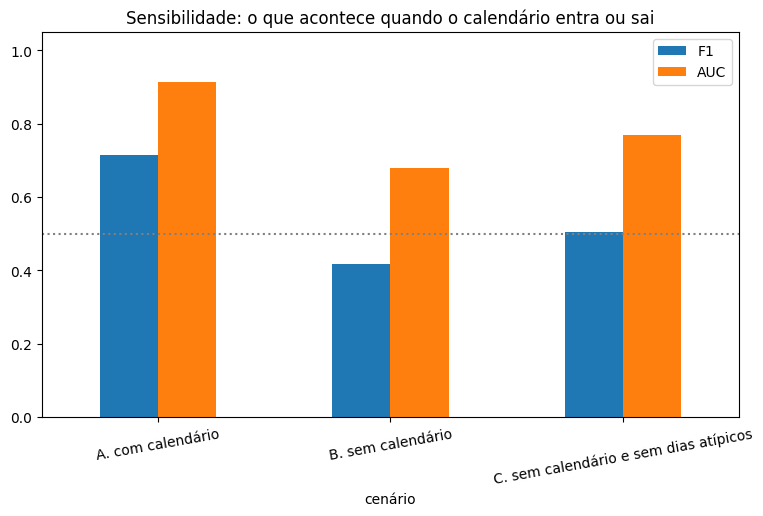

In [55]:
sens[['F1', 'AUC']].plot.bar(rot=10); plt.axhline(0.5, color='gray', linestyle=':')
plt.title('Sensibilidade: o que acontece quando o calendário entra ou sai'); plt.ylim(0, 1.05); plt.show()

## 8. Conclusão para o cidadão
A célula abaixo escreve o resumo com os **seus** números. Copie o texto e as tabelas para o relatório.

In [56]:
p = y_teste.mean()                                    # proporção real de atrasos no teste do modelo principal
rec, prec, auc = res.loc['recall', 'Teste'], res.loc['precisão', 'Teste'], res.loc['AUC', 'Teste']
top3 = list(tab_imp.head(3).index)                    # 3 variáveis mais importantes do modelo principal
forca = ('separa razoavelmente' if auc >= 0.70 else 'separa de forma modesta' if auc >= 0.60
         else 'quase não consegue separar')
n_txt = f'{len(teste):,}'.replace(',', '.')

print('O QUE ISSO SIGNIFICA PARA O CIDADÃO\n')
print(f'1) Em {n_txt} pedidos de limpeza urbana que o modelo nunca tinha visto, {p:.0%} demoraram mais do que '
      f'é normal para o mesmo tipo de serviço.')
print(f'2) Usando apenas tipo de serviço, canal, local e dia da semana, o modelo {forca} os pedidos que vão demorar '
      f'dos que não vão (AUC = {auc:.2f}; sortear daria 0,50).')
print(f'3) De cada 100 pedidos que de fato atrasaram, o modelo avisou {rec*100:.0f}. '
      f'De cada 100 avisos de atraso, {prec*100:.0f} eram atrasos de verdade.')
print(f'4) O que mais pesa na previsão: {", ".join(top3)}.')
if auc_A - auc_B > 0.10:
    print(f'5) Quando o modelo conhece o mês e o dia do mês em que o pedido foi aberto, o AUC sobe de {auc_B:.2f} para {auc_A:.2f}. '
          'Ou seja, boa parte da demora neste trimestre dependeu de QUANDO o pedido foi aberto (os atrasos se concentram em poucos '
          'períodos, ver seção 5b), e não de ONDE a pessoa mora ou do tipo de serviço. A base não informa a causa.')
else:
    print(f'5) Incluir mês e dia do mês muda pouco o resultado (AUC {auc_B:.2f} sem e {auc_A:.2f} com calendário).')
if auc < 0.60:
    print('6) Na prática: com estes dados, não dá para prever bem o atraso de um pedido novo. Isso também é um resultado: '
          'o atraso depende de fatores que o SP156 não registra (equipes, rotas, volume de chuva, tamanho da ocorrência).')
else:
    print('6) Na prática: o modelo pode ajudar a priorizar acompanhamento, mas não deve ser usado para negar ou adiar '
          'atendimento a ninguém.')
print('7) Atenção: a base mostra quem pediu, não onde existe o problema. Bairros com menos registros '
      'não são necessariamente bairros com menos lixo.')

O QUE ISSO SIGNIFICA PARA O CIDADÃO

1) Em 7.855 pedidos de limpeza urbana que o modelo nunca tinha visto, 22% demoraram mais do que é normal para o mesmo tipo de serviço.
2) Usando apenas tipo de serviço, canal, local e dia da semana, o modelo separa de forma modesta os pedidos que vão demorar dos que não vão (AUC = 0.68; sortear daria 0,50).
3) De cada 100 pedidos que de fato atrasaram, o modelo avisou 57. De cada 100 avisos de atraso, 33 eram atrasos de verdade.
4) O que mais pesa na previsão: dia_semana, Prefeitura Operacional, Assunto.
5) Quando o modelo conhece o mês e o dia do mês em que o pedido foi aberto, o AUC sobe de 0.68 para 0.91. Ou seja, boa parte da demora neste trimestre dependeu de QUANDO o pedido foi aberto (os atrasos se concentram em poucos períodos, ver seção 5b), e não de ONDE a pessoa mora ou do tipo de serviço. A base não informa a causa.
6) Na prática: o modelo pode ajudar a priorizar acompanhamento, mas não deve ser usado para negar ou adiar atendimento a ni

### Limitações (para o relatório)
- **Um único trimestre** e uma única cidade: o resultado não vale automaticamente para outros períodos (chuva, feriados, mutirões).
- **Episódios no calendário:** poucos dias concentram boa parte dos atrasos e das finalizações (seção 5b). A causa não consta na base; não a afirmamos.
- **Viés de registro:** pedidos refletem acesso e hábito de reclamar, não a quantidade real de problemas.
- **"Atraso" é relativo e curto:** é "mais demorado que 3 em cada 4 pedidos do mesmo serviço"; a mediana é de cerca de 1 dia e vários limites são de 0 a 2 dias. "Finalizada" pode significar fechamento administrativo do chamado, não necessariamente a limpeza feita na rua. Não é descumprimento de prazo oficial (use `PRAZO_CARTA` para testar com a Carta de Serviços).
- **Dias atípicos definidos olhando o resultado:** o cenário C é só sensibilidade, não é um filtro legítimo para produção.
- **Sem nº de protocolo:** linhas idênticas foram tratadas como o mesmo pedido, o que pode subestimar o volume.
- **Tempo em dias inteiros** (a base não traz hora) e **pedidos ainda abertos** ficam fora do modelo.
- A base **"Avaliação dos canais"** (satisfação) não foi usada; não verificamos se existe chave em comum com a base de solicitações.

## 9. Reprodutibilidade e fonte

In [57]:
FONTE_URL = 'https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156'
DATA_DOWNLOAD = '13 de novembro de 2026'
print('Fonte           :', FONTE_URL)
print('Arquivo         :', CAMINHO_CSV)
print('Baixado em      :', DATA_DOWNLOAD or '(preencher)')
print('Período (abertura):', PERIODO_INI.date(), 'a', PERIODO_FIM.date())
print('Última finalização na base:', DATA_CORTE.date())
print('Linhas na base inteira:', f'{N_BASE_TOTAL:,}', '| pedidos do tema:', f'{len(df_t):,}', '| usados no modelo:', f'{len(df_m):,}')
print('Semente:', SEED, '| USAR_CALENDARIO:', USAR_CALENDARIO, '| dias atípicos:', len(DIAS_ATIPICOS))
print('\nVersões (para o requirements.txt):')
for nome, mod in [('pandas', pd), ('numpy', np), ('scikit-learn', sklearn)]:
    print(f'{nome}=={mod.__version__}')
import matplotlib; print(f'matplotlib=={matplotlib.__version__}')
print('python', sys.version.split()[0])

Fonte           : https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156
Arquivo         : arquivo-final-3-trim-26.csv
Baixado em      : 13 de novembro de 2026
Período (abertura): 2026-07-01 a 2026-09-30
Última finalização na base: 2026-10-08
Linhas na base inteira: 484,232 | pedidos do tema: 54,312 | usados no modelo: 39,378
Semente: 42 | USAR_CALENDARIO: False | dias atípicos: 10

Versões (para o requirements.txt):
pandas==2.2.3
numpy==2.4.6
scikit-learn==1.6.1
matplotlib==3.10.0
python 3.13.18
